In [1]:
import os



def verifier_extensions(dossier):
    extensions = [".jpg", ".png", ".bmp",".jpeg",".txt"]
    invalides = []

    for racine, dossiers, fichiers in os.walk(dossier):
        for fichier in fichiers:
            ext = os.path.splitext(fichier)[1].lower()

            if ext not in extensions:
                path = os.path.join(racine, fichier)
                invalides.append(path)

    return invalides

res = verifier_extensions('../data')

for e in res:
    os.remove(e)
    print("Supprimé :", e)

In [2]:
path_dir="../data/1/Train"

# Parcourir les dossiers
for dossier in os.listdir(path_dir):
    chemin_dossier = os.path.join(path_dir, dossier)

    if os.path.isdir(chemin_dossier):
        elements = os.listdir(chemin_dossier)

        print(f"{dossier} : {len(elements)} éléments")


Meningioma : 2 éléments
Glioma : 2 éléments
Pituitary : 2 éléments
No Tumor : 2 éléments


In [3]:
import os
from pathlib import Path
import pandas as pd

# Chemin de base vers le dossier 'data'
BASE_DIR = Path("../data/1")
splits = ["Train", "Val"]

def get_dataset_dataframe(base_dir):
    base_path = Path(base_dir)
    
    if not base_path.exists():
        print(f"Le dossier {base_path} n'existe pas.")
        return None

    data = []

    for split in splits:
        split_path = base_path / split
        if not split_path.exists():
            continue
        
        # Parcourir chaque sous-dossier de catégorie (Glioma, Meningioma, No Tumor, Pituitary)
        for category_dir in sorted(split_path.iterdir()):
            if category_dir.is_dir():
                category_name = category_dir.name
                
                images_dir = category_dir / "images"
                labels_dir = category_dir / "labels"

                # Compter les fichiers
                num_images = len([f for f in images_dir.iterdir() if f.is_file()]) if images_dir.exists() else 0
                num_labels = len([f for f in labels_dir.iterdir() if f.is_file()]) if labels_dir.exists() else 0

                # Ajouter les informations dans la liste
                data.append({
                    "Split": split,
                    "Category": category_name,
                    "Images": num_images,
                    "Labels": num_labels,
                })

    # Création du DataFrame pandas
    df = pd.DataFrame(data)
    return df

if __name__ == "__main__":
    df_counts = get_dataset_dataframe(BASE_DIR)
    
    if df_counts is not None:
        # Affichage du DataFrame de manière élégante dans la console
        print("\n--- DataFrame des éléments par catégorie ---")
        print(df_counts.to_string(index=False))
        
        # Optionnel : Sauvegarder dans un fichier CSV si besoin
        # df_counts.to_csv("dataset_counts.csv", index=False)


--- DataFrame des éléments par catégorie ---
Split   Category  Images  Labels
Train     Glioma    1153    1153
Train Meningioma    1449    1449
Train   No Tumor     711     711
Train  Pituitary    1424    1424
  Val     Glioma     136     136
  Val Meningioma     140     140
  Val   No Tumor     100     100
  Val  Pituitary     136     136


Split                            ValValValVal
Category    GliomaMeningiomaNo TumorPituitary
Images                                    512
Labels                                    512
dtype: object

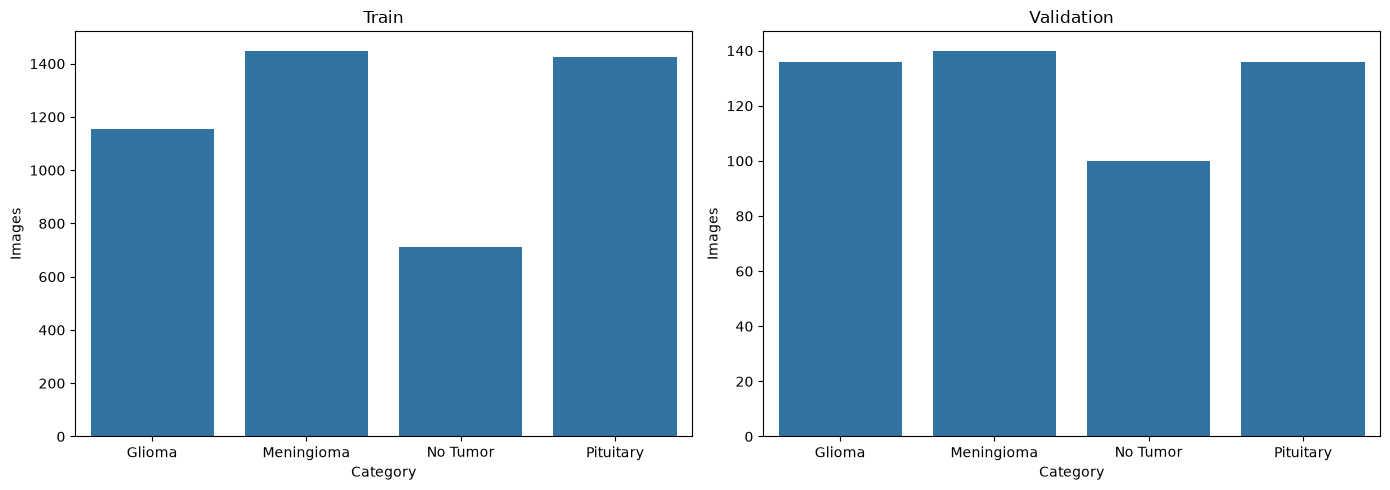

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique Train
sns.barplot(
    data=df_counts[df_counts["Split"] == "Train"],
    x="Category",
    y="Images",
    ax=axes[0]
)
axes[0].set_title("Train")

# Graphique Validation
sns.barplot(
    data=df_counts[df_counts["Split"] == "Val"],
    x="Category",
    y="Images",
    ax=axes[1]
)
axes[1].set_title("Validation")

plt.tight_layout()
plt.show()


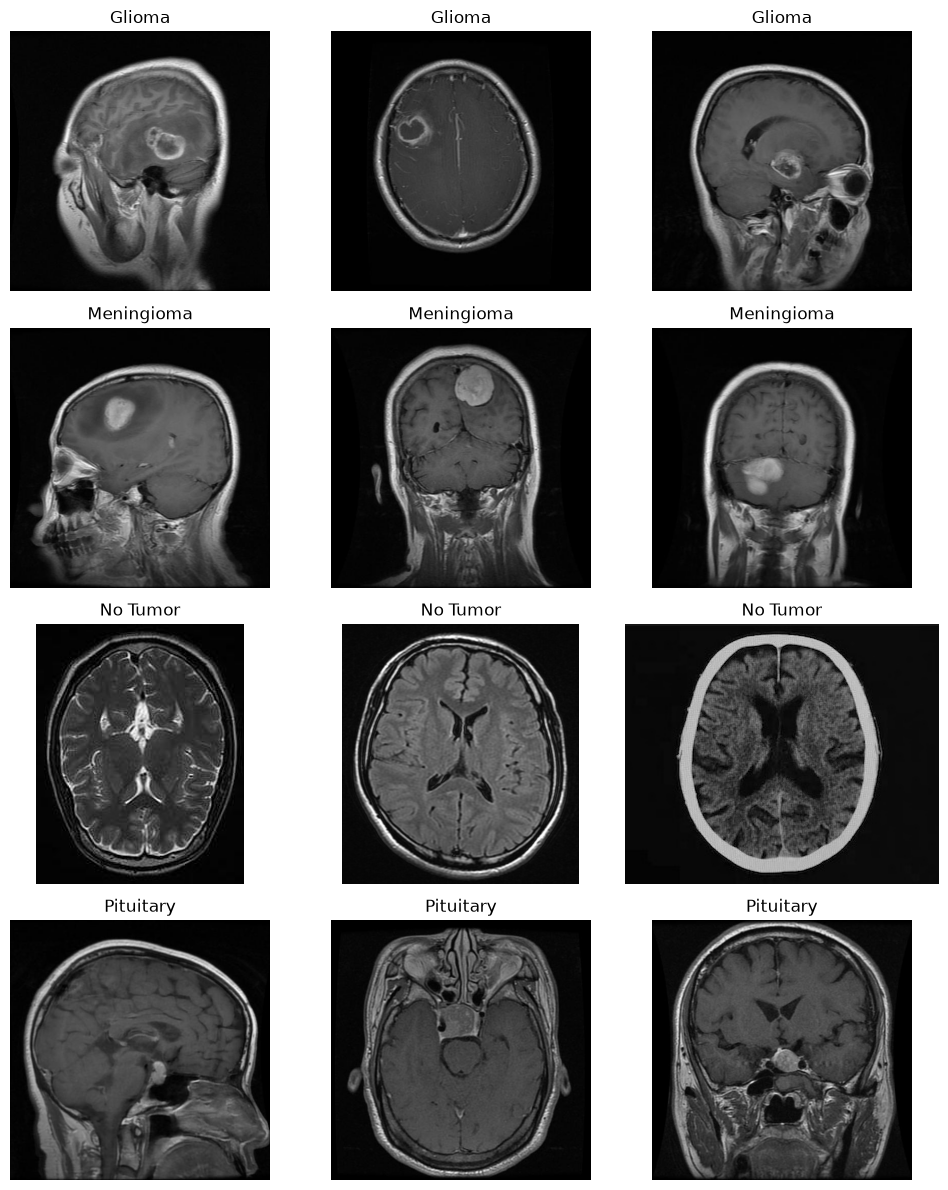

In [5]:

from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import random

# Dossier Train
base_dir = Path("../data/1/Train")

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for i, classe in enumerate(classes):
    images_dir = base_dir / classe / "images"

    # Récupérer les images
    images = list(images_dir.glob("*"))
    images = [
        p for p in images
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    # Choisir 3 images au hasard
    exemples = random.sample(images, min(3, len(images)))

    for j, chemin in enumerate(exemples):
        img = Image.open(chemin).convert("RGB")

        axes[i, j].imshow(img)
        axes[i, j].set_title(classe)
        axes[i, j].axis("off")

    # Masquer les cases vides
    for j in range(len(exemples), 3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()
